# 06 · Final pipeline

Two parts, kept separate so that their effects can be told apart:

- **A. Data and inference strategies** with a *fixed* trained model: NMS threshold, test-time augmentation, sliced inference, ensembling (WBF).
- **B. Model / training-data changes** with a *fixed* inference setting: more training frames, full augmentation, longer training.

Finally the chosen configuration is retrained on **all** labelled clips and used for the test submission.

## 1. Setup

In [1]:
import os, sys, json, shutil
from pathlib import Path

REPO = Path("/kaggle/working/repo") if Path("/kaggle").exists() else Path("..").resolve()
if Path("/kaggle").exists() and not REPO.exists():
    !git clone https://github.com/dd8ria/ai-hw2.git {REPO}
    !pip install -q faster-coco-eval ultralytics==8.3.*
sys.path.insert(0, str(REPO / "src"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.patches as patches, cv2
import vdet, parallel, ultra, infer
from vdet import CLASSES

vdet.seed_everything()
ROOT = vdet.find_data_root()
OUT = Path("/kaggle/working") if Path("/kaggle").exists() else REPO / "outputs"
RUNS = OUT / "runs"; RUNS.mkdir(parents=True, exist_ok=True)
RESULT_DIRS = [RUNS, REPO / "results"]   # own runs + runs committed by the teammate
P = vdet.PROTOCOL

# restore finished runs from earlier versions of this notebook (attached as Kaggle input)
for src in (Path("/kaggle/input").glob("*/runs/*") if Path("/kaggle/input").exists() else []):
    if (src / "config.json").exists() and not (RUNS / src.name).exists():
        shutil.copytree(src, RUNS / src.name); print("restored", src.name)

Cloning into '/kaggle/working/repo'...
remote: Enumerating objects: 227, done.
remote: Counting objects: 100% (227/227), done.
remote: Compressing objects: 100% (216/216), done.
remote: Total 227 (delta 88), reused 19 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (227/227), 43.14 MiB | 24.18 MiB/s, done.
Resolving deltas: 100% (88/88), done.


In [2]:
imgs, anns = vdet.load_all(ROOT)
folds = pd.read_csv(OUT / "folds.csv") if (OUT / "folds.csv").exists() else vdet.make_folds(imgs, P["n_folds"])
folds.to_csv(OUT / "folds.csv", index=False)   # the parallel runner reads the split from this file
train_frames, val_frames = vdet.protocol_frames(imgs, folds, P)
train_gt = anns[anns.key.isin(train_frames.key) & (anns.iscrowd == 0)]
print(json.dumps(P))
print(f"train: {len(train_frames)} frames | val: {len(val_frames)} frames / {val_frames.clip_uid.nunique()} clips")

COLS = ["AP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR_max", "ms_per_img", "epochs"]
def show(res, cols=COLS):
    cols = [c for c in cols if c in res]
    num = [c for c in cols if c not in ("ms_per_img", "epochs")]
    return res[cols].style.format("{:.4f}", subset=num).format("{:.1f}", subset=[c for c in ["ms_per_img"] if c in cols])

{"val_fold": 0, "n_folds": 5, "step": 10, "val_step": 10, "imgsz": 1280, "epochs": 12, "seed": 42}
train: 2189 frames | val: 545 frames / 12 clips


,AP,AP50,AP75,AP_small,AP_medium,AP_large,AR_max,ms_per_img,epochs
run,,,,,,,,,
frcnn_e1_proposals,0.2561,0.4795,0.2441,0.1094,0.2032,0.4448,0.3902,114.3,12
final_b2_fullaug,0.2366,0.4288,0.2264,0.1150,0.1773,0.3953,0.3514,17.5,12
yolo_y2_imgsz1536,0.2097,0.4052,0.1939,0.0926,0.1766,0.3248,0.3199,30.5,12
detr_d2_cost_giou,0.0563,0.1010,0.0561,0.0310,0.0408,0.1146,0.2404,87.3,12


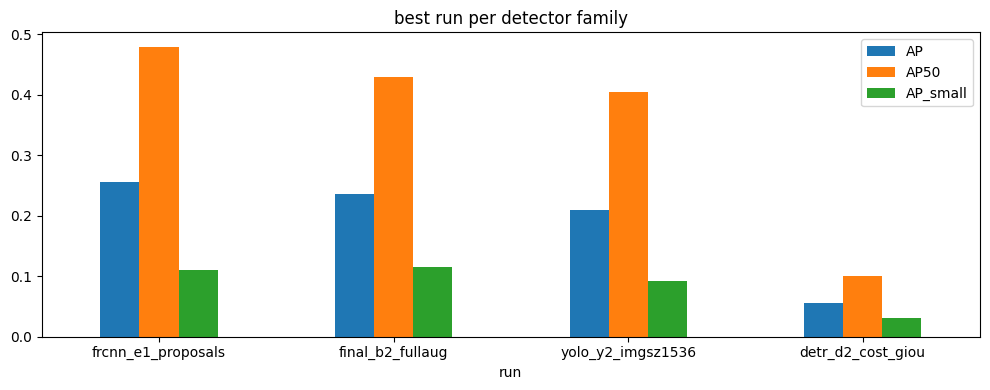

In [3]:
# All model results so far (own runs + teammate's committed results/)
allres = vdet.collect_results(RESULT_DIRS)
if len(allres):
    allres["family"] = allres.index.str.split("_").str[0]
    best = allres.loc[allres.groupby("family").AP.idxmax()].sort_values("AP", ascending=False)
    display(show(best, COLS))
    best[["AP", "AP50", "AP_small"]].plot.bar(figsize=(10, 4), rot=0, title="best run per detector family")
    plt.tight_layout(); plt.savefig(OUT / "summary_all_models.png", dpi=120); plt.show()

## 2. Part A — inference strategies on a fixed model

In [4]:
from pathlib import Path

root = Path("/kaggle/input/notebooks")

print("Notebooks folder exists:", root.exists())

for folder in root.glob("*/*"):
    print("\nNotebook:", folder)

    files = [
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in {".pt", ".pth", ".zip", ".ckpt"}
    ]

    print("Model files:", files[:30])

Notebooks folder exists: True

Notebook: /kaggle/input/notebooks/tttanyamoroz/06-part-b
Model files: []

Notebook: /kaggle/input/notebooks/dariaisme/04-yolo
Model files: [PosixPath('/kaggle/input/notebooks/dariaisme/04-yolo/results.zip'), PosixPath('/kaggle/input/notebooks/dariaisme/04-yolo/yolo11n.pt'), PosixPath('/kaggle/input/notebooks/dariaisme/04-yolo/yolov8s.pt'), PosixPath('/kaggle/input/notebooks/dariaisme/04-yolo/runs/yolo_y3_tal13/weights/best.pt'), PosixPath('/kaggle/input/notebooks/dariaisme/04-yolo/runs/yolo_y3_tal13/weights/last.pt'), PosixPath('/kaggle/input/notebooks/dariaisme/04-yolo/runs/yolo_y2_imgsz1536/weights/best.pt'), PosixPath('/kaggle/input/notebooks/dariaisme/04-yolo/runs/yolo_y2_imgsz1536/weights/last.pt'), PosixPath('/kaggle/input/notebooks/dariaisme/04-yolo/runs/yolo_y2_imgsz1024/weights/best.pt'), PosixPath('/kaggle/input/notebooks/dariaisme/04-yolo/runs/yolo_y2_imgsz1024/weights/last.pt'), PosixPath('/kaggle/input/notebooks/dariaisme/04-yolo/runs/yolo_y1

In [5]:
from pathlib import Path
import shutil

src = Path("/kaggle/input/notebooks/dariaisme/04-yolo/runs/yolo_y1_p2")
dst = RUNS / "yolo_y1_p2"

shutil.copytree(src, dst, dirs_exist_ok=True)

print("Config:", (dst / "config.json").exists())
print("Best weights:", (dst / "weights/best.pt").exists())
print("Model restored to:", dst)

Config: True
Best weights: True
Model restored to: /kaggle/working/runs/yolo_y1_p2


In [7]:
# The best single model. Its run folder must be available: own RUNS, or attach the teammate's
# Kaggle notebook output as input (the setup cell copies */runs/* automatically).
BASE_RUN = "yolo_y1_p2"
cfg = json.loads((RUNS / BASE_RUN / "config.json").read_text()); IMGSZ = cfg["imgsz"]
model = ultra.load(RUNS / BASE_RUN)
A = {}
def evalA(name, preds):
    A[name] = vdet.coco_evaluate(val_frames, anns, preds, per_class=False); print(name, {k: round(v, 4) for k, v in A[name].items()})
    return preds

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [8]:
# A1: NMS IoU threshold -- dense scenes have true neighbours that overlap
for iou in [0.5, 0.6, 0.7]:
    evalA(f"A1 nms_iou={iou}", ultra.predict_frames(model, val_frames, IMGSZ, iou=iou))

A1 nms_iou=0.5 {'AP': 0.1979, 'AP50': 0.3788, 'AP75': 0.1822, 'AP_small': 0.0807, 'AP_medium': 0.1591, 'AP_large': 0.3483, 'AR_max': 0.3133}
A1 nms_iou=0.6 {'AP': 0.199, 'AP50': 0.3794, 'AP75': 0.1836, 'AP_small': 0.081, 'AP_medium': 0.1603, 'AP_large': 0.3504, 'AR_max': 0.3183}
A1 nms_iou=0.7 {'AP': 0.1993, 'AP50': 0.3788, 'AP75': 0.184, 'AP_small': 0.081, 'AP_medium': 0.1608, 'AP_large': 0.3508, 'AR_max': 0.3249}


In [9]:
NMS_IOU = 0.7   # set from A1
# A2: test-time augmentation (Ultralytics: flips + 2 extra scales, merged before NMS)
evalA("A2 TTA", ultra.predict_frames(model, val_frames, IMGSZ, iou=NMS_IOU, augment=True))

A2 TTA {'AP': 0.2164, 'AP50': 0.4054, 'AP75': 0.2045, 'AP_small': 0.0852, 'AP_medium': 0.1713, 'AP_large': 0.3804, 'AR_max': 0.3672}


,key,cls,score,x,y,w,h
0,train/uav0000020_00406_v/0000001,0,0.905273,951.824951,487.987488,36.750000,101.587463
1,train/uav0000020_00406_v/0000001,0,0.886230,805.874939,397.949982,30.450012,79.799988
2,train/uav0000020_00406_v/0000001,0,0.880859,639.449951,382.724976,29.400024,77.700012
3,train/uav0000020_00406_v/0000001,0,0.861328,979.649963,507.674988,42.000000,110.250000
4,train/uav0000020_00406_v/0000001,0,0.858887,685.649963,363.824982,23.099976,57.750000
...,...,...,...,...,...,...,...
135744,val/uav0000117_02622_v/0000341,0,0.013847,2335.375000,640.156250,34.000000,72.250000
135745,val/uav0000117_02622_v/0000341,0,0.013634,2615.875000,786.250000,34.000000,89.250000
135746,val/uav0000117_02622_v/0000341,0,0.013535,2190.875000,413.046875,25.500000,48.343750
135747,val/uav0000117_02622_v/0000341,0,0.013535,2028.312500,495.656250,27.625000,52.593750


In [16]:
import json

with open(OUT / "part_a_metrics.json", "w") as f:
    json.dump(A, f, indent=2, default=float)

print("Saved:", OUT / "part_a_metrics.json")

Saved: /kaggle/working/part_a_metrics.json


In [13]:
# A3: sliced inference -- crops are upscaled to IMGSZ by the model, i.e. a zoom-in on tiny objects
fn = lambda ims: ultra.predict_images(model, ims, IMGSZ, iou=NMS_IOU)
for tile in [640, 960]:
    evalA(f"A3 sliced tile={tile}", infer.sliced_predict(fn, val_frames, tile=tile, overlap=0.2, full=True, merge_iou=NMS_IOU))

A3 sliced tile=640 {'AP': 0.1694, 'AP50': 0.3217, 'AP75': 0.1532, 'AP_small': 0.0774, 'AP_medium': 0.1325, 'AP_large': 0.3285, 'AR_max': 0.3606}


In [15]:
# A4: WBF ensemble of the best run of each family (saved val predictions -> no GPU needed)
pred_files = {}
for run in (best.index if len(allres) else []):
    f = next((Path(d) / run / "val_preds.csv.gz" for d in RESULT_DIRS if (Path(d) / run / "val_preds.csv.gz").exists()), None)
    if f is not None: pred_files[run] = f
print("models available for the ensemble:", list(pred_files))
val_preds = {r: pd.read_csv(f) for r, f in pred_files.items()}
order = sorted(val_preds, key=lambda r: -best.loc[r, "AP"])
for k in range(2, len(order) + 1):
    runs = order[:k]
    evalA(f"A4 WBF {'+'.join(runs)}", infer.wbf([val_preds[r] for r in runs], weights=[best.loc[r, "AP"] for r in runs], iou_thr=0.55))

models available for the ensemble: ['frcnn_e1_proposals', 'yolo_y2_imgsz1536']
A4 WBF frcnn_e1_proposals+yolo_y2_imgsz1536 {'AP': 0.2675, 'AP50': 0.4946, 'AP75': 0.2557, 'AP_small': 0.1167, 'AP_medium': 0.2223, 'AP_large': 0.4437, 'AR_max': 0.4106}


In [17]:
tabA = pd.DataFrame(A).T[["AP", "AP50", "AP_small", "AP_medium"]]
display(tabA.style.format("{:.4f}").highlight_max(color="#cde"))

,AP,AP50,AP_small,AP_medium
A1 nms_iou=0.5,0.1979,0.3788,0.0807,0.1591
A1 nms_iou=0.6,0.1990,0.3794,0.0810,0.1603
A1 nms_iou=0.7,0.1993,0.3788,0.0810,0.1608
A2 TTA,0.2164,0.4054,0.0852,0.1713
A3 sliced tile=960,0.1978,0.3839,0.0833,0.1640
A3 sliced tile=640,0.1694,0.3217,0.0774,0.1325
A4 WBF frcnn_e1_proposals+yolo_y2_imgsz1536,0.2675,0.4946,0.1167,0.2223


## 3. Part B — training data / model changes with fixed inference

In [ ]:
# B1: denser frame sampling (step 5 instead of 10); B2: full Ultralytics augmentation (mosaic, scale, HSV);
# B3: longer training. All on the BASE_RUN architecture, evaluated with plain inference.
data5 = vdet.build_yolo_dataset(imgs, anns, folds, val_fold=P["val_fold"], out_dir=OUT / "yolo_fold0_step5",
                                step=5, val_step=P["val_step"])
data10 = OUT / "yolo_fold0" / "data.yaml"
if not data10.exists():
    data10 = vdet.build_yolo_dataset(imgs, anns, folds, val_fold=P["val_fold"], out_dir=OUT / "yolo_fold0",
                                     step=P["step"], val_step=P["val_step"])
FULL_AUG = dict(mosaic=1.0, scale=0.5, translate=0.1, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, close_mosaic=3)
B = {"final_b1_step5": (data5, {**cfg}),
     "final_b2_fullaug": (data10, {**cfg, "aug": FULL_AUG}),
     "final_b3_24ep": (data10, {**cfg, "epochs": 2 * cfg["epochs"]})}
RUN_B = ["final_b1_step5", "final_b2_fullaug", "final_b3_24ep"]
# each job carries its own dataset; with 2 GPUs b1 + b2 run together, then b3
parallel.run_parallel([(n, B[n][1], B[n][0]) for n in RUN_B], RUNS, folds_csv=OUT / "folds.csv")
display(show(pd.concat([vdet.collect_results(RESULT_DIRS, BASE_RUN), vdet.collect_results(RESULT_DIRS, "final_b")])))

In [18]:
b = vdet.collect_results(RESULT_DIRS, "final_b")

if len(b):
    display(b[["AP", "AP50", "AP_small", "epochs"]])
else:
    print("Part B results not found")

,AP,AP50,AP_small,epochs
run,,,,
final_b1_step5,0.192479,0.346381,0.071550,12
final_b2_fullaug,0.236560,0.428766,0.115001,12
final_b3_24ep,0.192097,0.347969,0.092535,24


## 4. Final model: chosen settings, trained on all labelled clips

In [ ]:
FULL_AUG = dict(
    mosaic=1.0,
    scale=0.5,
    translate=0.1,
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,
    close_mosaic=3
)

FINAL_CFG = {**cfg, "aug": FULL_AUG, "batch": 1}
FINAL_STEP = P["step"]               
data_all = vdet.build_yolo_dataset(imgs, anns, folds, val_fold=P["val_fold"], out_dir=OUT / "yolo_all",
                                   step=FINAL_STEP, val_step=P["val_step"], train_all=True)
# val metrics of this run are optimistic (holdout is in training); they are only a sanity check
parallel.run_parallel([("final_all_clips", FINAL_CFG)], RUNS, folds_csv=OUT / "folds.csv", data_yaml=data_all)

train:   2734 frames,  1979 masked copies
val  :    545 frames,   409 masked copies
1 jobs on GPUs [0, 1]
[   0.0 min] started final_all_clips on GPU 0
[   0.5 min] final_all_clips (GPU 0):        1/12      3.26G      4.177      5.631      4.376         72       1280: 1% ──────────── 29/2734 7.4it/s 5.4s<6:03
[  10.5 min] final_all_clips (GPU 0):        2/12      4.56G      1.931      1.993      2.116         47       1280: 76% ━━━━━━━━━─── 2091/2734 8.7it/s 4:10<1:14


In [1]:
from pathlib import Path

p = Path("/kaggle/working/runs/final_all_clips")
print("Folder:", p.exists())
print("Checkpoints:", list(p.rglob("*.pt")) if p.exists() else [])

Folder: False
Checkpoints: []


In [ ]:
# Test predictions with the inference strategy chosen in Part A
final = ultra.load(RUNS / "final_all_clips")
test = pd.read_csv(ROOT / "test_images.csv")
test_frames = test.assign(key=test.image_id, img_path=[str(ROOT / f) for f in test.file_name])
STRATEGY = "plain"   # "plain", "tta" or "sliced", from Part A
if STRATEGY == "sliced":
    fn = lambda ims: ultra.predict_images(final, ims, FINAL_CFG["imgsz"], iou=NMS_IOU)
    tp = infer.sliced_predict(fn, test_frames, tile=640, overlap=0.2, merge_iou=NMS_IOU)
else:
    tp = ultra.predict_frames(final, test_frames, FINAL_CFG["imgsz"], iou=NMS_IOU, augment=STRATEGY == "tta")
tp = tp.rename(columns={"key": "image_id"})
tp.to_csv(OUT / "test_preds_final.csv.gz", index=False)
vdet.write_submission(tp, ROOT / "test_images.csv", OUT / "submission_final.csv")

In [ ]:
# Optional: WBF of the final model with other models' test predictions (files written by notebooks 02-05;
# attach those notebook outputs as inputs). Use only if A4 showed a gain on the holdout.
others = sorted(Path("/kaggle/input").glob("*/test_preds_*.csv.gz")) if Path("/kaggle/input").exists() else []
print([o.name for o in others])
if others:
    parts = [tp] + [pd.read_csv(o) for o in others]
    fused = infer.wbf([p.rename(columns={"image_id": "key"}) for p in parts], iou_thr=0.55).rename(columns={"key": "image_id"})
    vdet.write_submission(fused, ROOT / "test_images.csv", OUT / "submission_final_wbf.csv")

In [ ]:
# Results for the repo: unzip results.zip from the notebook Output into <repo>/results/ and commit.
vdet.export_results(RUNS, OUT / "results", preds_for=("final_all_clips",))